# Post-Training Alignment: RLHF, DPO, and Group Relative Policy Optimization (GRPO)

## 1. Overview & The Alignment Problem
Pre-trained and instruction-tuned language models can generate fluent text, but raw next-token prediction does not guarantee that models are **Helpful, Honest, and Harmless (the 3 Hs)**.

To align LLM behaviors with human values and reasoning constraints, modern NLP has evolved through three distinct generations of post-training alignment:

```
[Pre-trained LLM] ──> [Supervised Fine-Tuning (SFT)] ──> [Alignment Pipeline]
                                                               │
        ┌──────────────────────────────────────────────────────┼────────────────────────────────────────┐
        ▼                                                      ▼                                        ▼
[Generation 1: RLHF with PPO]                  [Generation 2: Direct Preference (DPO)]   [Generation 3: Group Relative (GRPO)]
 • Requires 4 models in VRAM                    • Closed-form implicit reward             • DeepSeek-R1 reasoning breakthrough
 • Actor, Critic, Ref, Reward                   • Eliminates Actor-Critic & RL            • Eliminates Critic model entirely
 • PPO clipped surrogate loss                   • Trains directly on (y_w > y_l)          • Group-normalized advantage over G samples
 • High variance, compute-heavy                 • Stable, fast, memory-efficient          • Ideal for math, code, and reasoning
```

### What We Will Master:
1. **Generation 1 (RLHF with PPO)**: The 3-stage pipeline (SFT $\to$ Reward Model $\to$ PPO with KL divergence penalty).
2. **Generation 2 (Direct Preference Optimization - DPO)**: Deriving the closed-form implicit reward and training with TRL's `DPOTrainer`.
3. **Generation 3 (Group Relative Policy Optimization - GRPO)**: The DeepSeek-R1 breakthrough for verifiable reasoning without a critic model.
4. **Comparative Architectural Matrix**: Side-by-side trade-offs in stability, compute, and performance.

---
## 1. Reinforcement Learning from Human Feedback (RLHF with PPO)

RLHF aligns models using a learned scalar reward model and reinforcement learning via Proximal Policy Optimization (PPO).

### The 3 Stages of RLHF:
1. **Stage 1 (SFT)**: Fine-tune base model on high-quality instruction demonstrations.
2. **Stage 2 (Reward Modeling)**: Train a separate model $r_\psi(x, y)$ on pairwise human comparisons ($y_w \succ y_l$) using Bradley-Terry preference loss:
   $$\mathcal{L}_R = -\mathbb{E}\left[\log \sigma(r_\psi(x, y_w) - r_\psi(x, y_l))\right]$$
3. **Stage 3 (PPO Optimization)**: Optimize the policy model $\pi_\theta$ to maximize reward while penalizing drift from the reference policy via KL divergence:
   $$\text{Objective} = \mathbb{E}\left[r_\psi(x, y) - \beta \mathbb{D}_{KL}(\pi_\theta(y|x) \parallel \pi_{ref}(y|x))\right]$$

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

warnings.filterwarnings("ignore", category=UserWarning)


## Stage 1 — Supervised Fine-Tuning (SFT)

The SFT model is the starting point.  We treat **GPT-2** (already pretrained
on large-scale text) as our SFT baseline and show what it generates *before*
RLHF alignment.


In [2]:
model_name = "gpt2"
tokenizer  = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token

sft_model  = AutoModelForCausalLM.from_pretrained(model_name)

def generate(model, prompt, max_new_tokens=40, temperature=0.9):
    # Put inputs on the model's device (PPOTrainer may move the policy to MPS/GPU)
    enc = tokenizer(prompt, return_tensors="pt").to(model.device)
    ids = enc.input_ids
    with torch.no_grad():
        out = model.generate(
            ids, attention_mask=enc.attention_mask, max_new_tokens=max_new_tokens,
            do_sample=True, temperature=temperature,
            pad_token_id=tokenizer.eos_token_id,
        )
    return tokenizer.decode(out[0].cpu(), skip_special_tokens=True)

prompts = ["The movie was", "I watched the film and", "This documentary"]
print("=== SFT outputs (before RLHF) ===")
for p in prompts:
    print(f"  {p!r:35s} → {generate(sft_model, p)}")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

=== SFT outputs (before RLHF) ===
  'The movie was'                     → The movie was shot in a studio in Hong Kong and released to the world on 4Chan, a social network with the potential to ignite controversy. On Sunday, the group of activists launched a YouTube video calling for the
  'I watched the film and'            → I watched the film and thought that it might be a part of something important."

"I would love to see the films make it to the big screens. I also want to see it in theatres. You can
  'This documentary'                  → This documentary explores the issues that lead to a national crisis for the LGBT community and to its potential impact on the future generation of Americans in and out of the workforce. This documentary explores the issues that lead to a


## Stage 2 — Reward Model

The reward model $r_\phi(x, y) \to \mathbb{R}$ is trained to score responses
according to human preferences via the **Bradley-Terry** objective:

$$\mathcal{L}_{RM} = -\mathbb{E}_{(x,y_w,y_l)} \bigl[\log \sigma\bigl(r_\phi(x,y_w) - r_\phi(x,y_l)\bigr)\bigr]$$

For this demo we use a **sentiment classifier** as a proxy reward:
positive sentiment → high reward, negative → low reward.  In production,
this model is trained on thousands of human preference annotations.


In [3]:
reward_pipe = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=-1,
)

def compute_reward(texts: list[str]) -> list[torch.Tensor]:
    results = reward_pipe(texts, truncation=True, max_length=256)
    return [
        torch.tensor(r["score"] if r["label"] == "POSITIVE" else -r["score"])
        for r in results
    ]

examples = [
    "This movie was absolutely wonderful and moving.",
    "The film was dull and a complete waste of time.",
    "An incredible performance by every actor.",
    "Terrible pacing and a nonsensical ending.",
]
print("=== Reward model test ===")
for text, r in zip(examples, compute_reward(examples)):
    sign = "" if r.item() > 0 else ""
    print(f"  {sign} reward={r.item():+.3f}  {text}")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

=== Reward model test ===
   reward=+1.000  This movie was absolutely wonderful and moving.
   reward=-1.000  The film was dull and a complete waste of time.
   reward=+1.000  An incredible performance by every actor.
   reward=-1.000  Terrible pacing and a nonsensical ending.


## Stage 3 — PPO: Proximal Policy Optimization

PPO maximises expected reward while keeping the new policy $\pi_\theta$ close
to the reference SFT policy $\pi_\text{ref}$ via a KL penalty:

$$\mathcal{L}_\text{PPO} = \mathbb{E}\!\left[\min\!\left(r_t \hat{A}_t,\; \text{clip}(r_t, 1{-}\epsilon, 1{+}\epsilon)\hat{A}_t\right)\right] - \beta\,\mathbb{D}_{KL}[\pi_\theta \| \pi_\text{ref}]$$

where $r_t = \pi_\theta(a_t|s_t)/\pi_\text{old}(a_t|s_t)$ is the probability
ratio and $\hat{A}_t$ is the advantage estimate from the **value/critic head**.

The **clip** prevents excessively large policy updates (trust region).


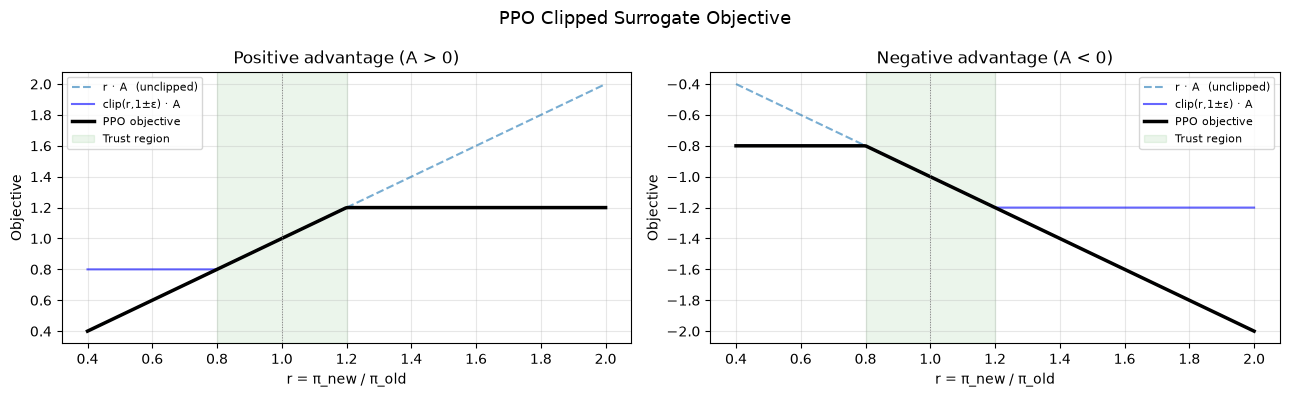

Ratios : [0.8187307119369507, 1.2214027643203735, 0.6065306663513184, 1.0]
PPO loss: -0.2023


In [4]:
# ── Implement the PPO clipped surrogate loss ─────────────────────────────────
def ppo_clipped_loss(log_p_new, log_p_old, adv, eps=0.2):
    ratio  = torch.exp(log_p_new - log_p_old)          # π_new / π_old
    surr1  = ratio * adv
    surr2  = torch.clamp(ratio, 1.0 - eps, 1.0 + eps) * adv
    return -torch.min(surr1, surr2).mean(), ratio       # negate → gradient ascent

# ── Visualise clipping behaviour ──────────────────────────────────────────────
rs  = np.linspace(0.4, 2.0, 300)
eps = 0.2

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, A, title in zip(axes, [1.0, -1.0],
                         ["Positive advantage (A > 0)", "Negative advantage (A < 0)"]):
    s1 = rs * A
    s2 = np.clip(rs, 1 - eps, 1 + eps) * A
    ax.plot(rs, s1, "--", alpha=0.6, label="r · A  (unclipped)")
    ax.plot(rs, s2, "b-", alpha=0.6, label="clip(r,1±ε) · A")
    ax.plot(rs, np.minimum(s1, s2), "k-", lw=2.5, label="PPO objective")
    ax.axvspan(1-eps, 1+eps, alpha=0.08, color="green", label="Trust region")
    ax.axvline(1.0, color="gray", lw=0.7, ls=":")
    ax.set(xlabel="r = π_new / π_old", ylabel="Objective", title=title)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle("PPO Clipped Surrogate Objective", fontsize=13)
plt.tight_layout(); plt.show()

# ── Quick numerical demo ───────────────────────────────────────────────────────
log_new = torch.tensor([-1.2, -0.8, -1.5, -1.0])
log_old = torch.tensor([-1.0, -1.0, -1.0, -1.0])
adv     = torch.tensor([ 0.5,  1.2, -0.3, -0.8])
loss, ratios = ppo_clipped_loss(log_new, log_old, adv)
print(f"Ratios : {ratios.tolist()}")
print(f"PPO loss: {loss.item():.4f}")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

PPO training …
  iter  1/12  mean reward = +0.015
  iter  2/12  mean reward = -0.729
  iter  3/12  mean reward = +0.497
  iter  4/12  mean reward = +0.250
  iter  5/12  mean reward = +0.733
  iter  6/12  mean reward = +0.703
  iter  7/12  mean reward = +0.727
  iter  8/12  mean reward = +0.503
  iter  9/12  mean reward = -0.066
  iter 10/12  mean reward = +0.509
  iter 11/12  mean reward = +0.237
  iter 12/12  mean reward = +0.518
Done.


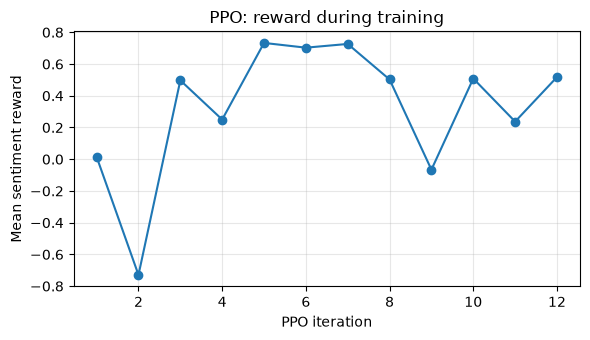


[Before PPO] The movie was not finished, but it was close. The film was to be shown at the New Year's Eve party in NYC, but Paramount was not willing to make a deal with it. The movie's stars
[After  PPO] The movie was filmed in the first year of its release, an annual screening of Star Wars and a production of the movie by the National Book Award winner in New York, when the film began its third-season schedule


In [5]:
# ── Minimal PPO-RLHF loop in plain PyTorch (new TRL no longer ships PPOTrainer) ──
# Policy = GPT-2 + value head, Ref = frozen GPT-2, Reward = sentiment classifier
# from the Reward Model cell (compute_reward).
import copy

ppo_model = AutoModelForCausalLM.from_pretrained("gpt2").eval()   # eval() → dropout off, ratio=1 at start
ref_model = copy.deepcopy(ppo_model).eval()
for p in ref_model.parameters():
    p.requires_grad_(False)
value_head = torch.nn.Linear(ppo_model.config.n_embd, 1)          # critic: V(s_t)

movie_prompts = [
    "The movie was", "I watched the film and", "The acting in this movie",
    "This film made me feel", "The director created a", "The story was",
    "The performances were", "After watching this movie,",
]
RESP_LEN, KL_COEF, EPS = 20, 0.2, 0.2
GAMMA, LAM, PPO_EPOCHS, ITERS = 1.0, 0.95, 4, 12

optimizer = torch.optim.AdamW([
    {"params": ppo_model.parameters(), "lr": 1.41e-5},
    {"params": value_head.parameters(), "lr": 1e-3},
])

def token_stats(model, ids, n_prompt, with_value=False):
    """Per-response-token log-probs (and values) for one sequence ids: (1, T)."""
    out  = model(ids, output_hidden_states=with_value)
    logp = F.log_softmax(out.logits[:, :-1], -1).gather(-1, ids[:, 1:, None]).squeeze(-1)
    logp = logp[0, n_prompt - 1:]                                  # response tokens only
    if not with_value:
        return logp
    v = value_head(out.hidden_states[-1][:, :-1]).squeeze(-1)[0, n_prompt - 1:]
    return logp, v

def gae(rewards, values):
    adv, last = torch.zeros_like(rewards), 0.0
    for t in reversed(range(len(rewards))):
        nxt   = values[t + 1] if t + 1 < len(values) else 0.0
        delta = rewards[t] + GAMMA * nxt - values[t]
        last  = delta + GAMMA * LAM * last
        adv[t] = last
    return adv

history = []
print("PPO training …")
for it in range(ITERS):
    # ── 1. Rollout: sample a response per prompt, score it, build token rewards ──
    batch = []
    for prompt in movie_prompts:
        ids = tokenizer(prompt, return_tensors="pt").input_ids
        n_prompt = ids.shape[1]
        with torch.no_grad():
            seq = ppo_model.generate(
                ids, attention_mask=torch.ones_like(ids), do_sample=True,
                temperature=0.9, top_k=0, max_new_tokens=RESP_LEN,
                min_new_tokens=RESP_LEN, pad_token_id=tokenizer.eos_token_id)
            old_logp, old_v = token_stats(ppo_model, seq, n_prompt, with_value=True)
            ref_logp = token_stats(ref_model, seq, n_prompt)
        score = compute_reward([tokenizer.decode(seq[0, n_prompt:], skip_special_tokens=True)])[0]
        rewards = -KL_COEF * (old_logp - ref_logp)                 # per-token KL penalty
        rewards[-1] += score                                       # sentiment reward at the end
        adv = gae(rewards, old_v)
        batch.append(dict(seq=seq, n=n_prompt, old_logp=old_logp,
                          adv=adv, ret=adv + old_v, score=score.item()))
    all_adv = torch.cat([b["adv"] for b in batch])
    mu, sd = all_adv.mean(), all_adv.std().clamp(min=1e-8)

    # ── 2. Optimise: several epochs of clipped PPO on the same rollouts ──
    for _ in range(PPO_EPOCHS):
        optimizer.zero_grad()
        for b in batch:
            logp, v = token_stats(ppo_model, b["seq"], b["n"], with_value=True)
            a = (b["adv"] - mu) / sd
            ratio = torch.exp(logp - b["old_logp"])
            pg = -torch.min(ratio * a, torch.clamp(ratio, 1 - EPS, 1 + EPS) * a).mean()
            vf = F.mse_loss(v, b["ret"])
            ((pg + 0.5 * vf) / len(batch)).backward()
        torch.nn.utils.clip_grad_norm_(ppo_model.parameters(), 1.0)
        optimizer.step()

    history.append(np.mean([b["score"] for b in batch]))
    print(f"  iter {it+1:2d}/{ITERS}  mean reward = {history[-1]:+.3f}")
print("Done.")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, ITERS + 1), history, "o-")
plt.xlabel("PPO iteration"); plt.ylabel("Mean sentiment reward")
plt.title("PPO: reward during training"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ── Before vs after comparison ────────────────────────────────────────────────
prompt = "The movie was"
print(f"\n[Before PPO] {generate(sft_model, prompt)}")
print(f"[After  PPO] {generate(ppo_model,  prompt)}")


---
## 2. Direct Preference Optimization (DPO) — RLHF Without Reinforcement Learning

While PPO works, it is notoriously unstable, sensitive to hyperparameters, and requires holding **4 full models in GPU memory** simultaneously (Policy, Reference, Critic, and Reward model).

**DPO (Rafailov et al., 2023)** observed that the optimal policy under the RLHF objective has a closed-form analytical relationship with the ground-truth reward:
$$r(x, y) = \beta \log \frac{\pi_\theta(y|x)}{\pi_{ref}(y|x)}$$

Substituting this directly into the Bradley-Terry preference loss eliminates the reward model and RL loop entirely:
$$\mathcal{L}_{DPO}(\pi_\theta; \pi_{ref}) = -\mathbb{E}_{(x, y_w, y_l)}\left[\log \sigma\left(\beta \log \frac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)} - \beta \log \frac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\right)\right]$$

## DPO Loss — Manual Implementation

The loss only needs the **log-probs** of chosen and rejected responses under
the current policy and the frozen reference policy.


In [6]:
def log_prob_of_sequence(model, input_ids: torch.Tensor) -> torch.Tensor:
    """Sum of log-probs of each token given its prefix (teacher-forcing)."""
    with torch.no_grad():
        logits = model(input_ids).logits            # (1, T, V)
    log_probs = F.log_softmax(logits, dim=-1)       # (1, T, V)
    # Shift: predict token t from tokens 0..t-1
    target_ids = input_ids[:, 1:]                   # (1, T-1)
    gathered   = log_probs[:, :-1, :].gather(-1, target_ids.unsqueeze(-1)).squeeze(-1)
    return gathered.sum()                           # scalar


def dpo_loss(policy, ref_model, tokenizer, chosen: str, rejected: str,
             prompt: str, beta: float = 0.1) -> torch.Tensor:
    full_chosen   = prompt + chosen
    full_rejected = prompt + rejected

    ids_c = tokenizer(full_chosen,   return_tensors="pt").input_ids
    ids_r = tokenizer(full_rejected, return_tensors="pt").input_ids
    ids_p = tokenizer(prompt,        return_tensors="pt").input_ids
    prompt_len = ids_p.shape[1]

    # Current policy log-probs (only over the response tokens)
    def response_logp(model, full_ids):
        lp = log_prob_of_sequence(model, full_ids)
        lp_prompt = log_prob_of_sequence(model, full_ids[:, :prompt_len])
        return lp - lp_prompt

    pi_logp_w  = response_logp(policy,    ids_c)
    pi_logp_l  = response_logp(policy,    ids_r)
    ref_logp_w = response_logp(ref_model, ids_c)
    ref_logp_l = response_logp(ref_model, ids_r)

    # Implicit reward difference
    reward_w = beta * (pi_logp_w - ref_logp_w)
    reward_l = beta * (pi_logp_l - ref_logp_l)

    loss = -F.logsigmoid(reward_w - reward_l)
    return loss, reward_w.item(), reward_l.item()


# ── Demo with a tiny preference trio ────────────────────────────────────────
model_name = "gpt2"
tokenizer  = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token

policy    = AutoModelForCausalLM.from_pretrained(model_name)
ref_model = AutoModelForCausalLM.from_pretrained(model_name)

prompt   = "Question: What is the capital of France?\nAnswer:"
chosen   = " Paris is the capital of France."
rejected = " I don't know, maybe London?"

loss, rw, rl = dpo_loss(policy, ref_model, tokenizer, chosen, rejected, prompt)
print(f"DPO loss    : {loss.item():.4f}")
print(f"Reward(chosen)  : {rw:+.4f}")
print(f"Reward(rejected): {rl:+.4f}")
print(f"Reward gap  : {rw - rl:+.4f}  ← positive means model already prefers chosen")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

DPO loss    : 0.6931
Reward(chosen)  : +0.0000
Reward(rejected): +0.0000
Reward gap  : +0.0000  ← positive means model already prefers chosen


## DPO Training with TRL

TRL's `DPOTrainer` handles the batching, reference-model log-prob caching,
and gradient updates automatically.  The dataset must have three columns:
`prompt`, `chosen`, `rejected`.


In [7]:
from datasets import Dataset
from trl import DPOConfig, DPOTrainer

# ── Toy preference dataset ────────────────────────────────────────────────────
data = {
    "prompt": [
        "What is the capital of France?",
        "Explain what a neural network is.",
        "How do you say hello in Spanish?",
        "What is 2 + 2?",
        "Name a primary colour.",
        "What does HTTP stand for?",
    ],
    "chosen": [
        "The capital of France is Paris, a beautiful city on the Seine river.",
        "A neural network is a computational model inspired by the human brain, composed of layers of interconnected nodes that learn by adjusting weights during training.",
        "In Spanish, hello is 'Hola'.",
        "2 + 2 equals 4.",
        "Red is a primary colour.",
        "HTTP stands for HyperText Transfer Protocol.",
    ],
    "rejected": [
        "I'm not sure, possibly Berlin?",
        "It's a type of fish.",
        "I don't speak Spanish.",
        "I cannot do maths.",
        "Purple is a primary colour.",
        "HTTP is a type of car.",
    ],
}
dataset = Dataset.from_dict(data)

# ── Load models explicitly (avoids string-loading ambiguity in TRL >= 0.27) ──
# Older TRL accepted model_name strings; newer versions require model objects
# or None (None means use LoRA adapters as implicit reference).
policy_model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.float32)
ref_model_dpo = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.float32)

# ── DPO config ────────────────────────────────────────────────────────────────
dpo_config = DPOConfig(
    output_dir="./dpo_output",
    beta=0.1,                       # KL regularisation strength
    max_length=128,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=2,
    num_train_epochs=2,
    learning_rate=5e-5,
    logging_steps=1,
    remove_unused_columns=False,
    report_to="none",
)

dpo_trainer = DPOTrainer(
    model=policy_model,
    ref_model=ref_model_dpo,
    args=dpo_config,
    train_dataset=dataset,
    processing_class=tokenizer,
)

print("Training DPO …")
dpo_trainer.train()
print("Done.")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Adding EOS to train dataset:   0%|          | 0/6 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/6 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/6 [00:00<?, ? examples/s]

Training DPO …


Step,Training Loss
1,0.697484
2,0.611363
3,0.663979
4,0.218123
5,0.211928
6,0.062548


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Done.


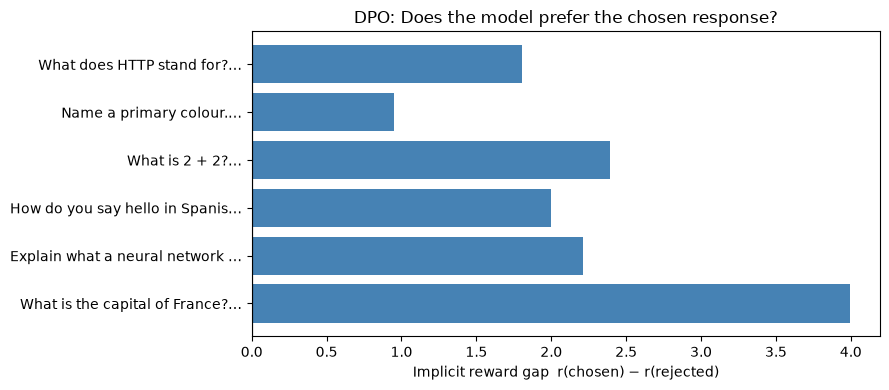

Model prefers chosen response in 6/6 examples


In [8]:
# ── Visualise implicit reward gap over the training set ──────────────────────
# Accelerate may move the trained model to MPS during training; move both
# models to CPU first so devices always match regardless of backend.
trained_model = dpo_trainer.model.cpu().eval()
ref_model_dpo = ref_model_dpo.cpu()

reward_gaps = []
for i in range(len(data["prompt"])):
    _, rw, rl = dpo_loss(
        trained_model, ref_model_dpo, tokenizer,
        data["chosen"][i], data["rejected"][i], data["prompt"][i],
    )
    reward_gaps.append(rw - rl)

colors = ["steelblue" if g > 0 else "salmon" for g in reward_gaps]
labels = [p[:30] + "…" for p in data["prompt"]]

plt.figure(figsize=(9, 4))
bars = plt.barh(labels, reward_gaps, color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Implicit reward gap  r(chosen) − r(rejected)")
plt.title("DPO: Does the model prefer the chosen response?")
plt.tight_layout(); plt.show()

positive = sum(g > 0 for g in reward_gaps)
print(f"Model prefers chosen response in {positive}/{len(reward_gaps)} examples")


---
## 3. Group Relative Policy Optimization (GRPO) — The DeepSeek Reasoning Breakthrough

In mathematical problem-solving, code synthesis, and logical reasoning, verifiable rule-based outcomes exist (e.g. unit tests pass, math equation is correct). 

Introduced by DeepSeek in **DeepSeekMath** and used to train **DeepSeek-R1**, **GRPO** eliminates the Value/Critic network completely, drastically reducing memory overhead:

### How GRPO Works:
1. For each prompt $q$, the policy generates a **group of $G$ candidate outputs**: $\{o_1, o_2, \dots, o_G\}$.
2. Each output receives a reward score $r_i$ from rule-based verifiers or reward functions.
3. Compute the **group-normalized relative advantage**:
   $$\tilde{A}_i = \frac{r_i - \text{mean}(\{r_1, \dots, r_G\})}{\text{std}(\{r_1, \dots, r_G\}) + \epsilon}$$
4. Outputs that perform better than the group average receive positive updates; below-average outputs receive negative updates.

## GRPO From Scratch

Let's implement the core advantage calculation and policy-gradient step
to understand what GRPO is doing.


Rewards     : ['0.10', '0.80', '0.20', '0.90', '0.30', '0.60']
Advantages  : ['-1.16', '0.96', '-0.86', '1.26', '-0.55', '0.35']

GRPO loss   : 0.0279


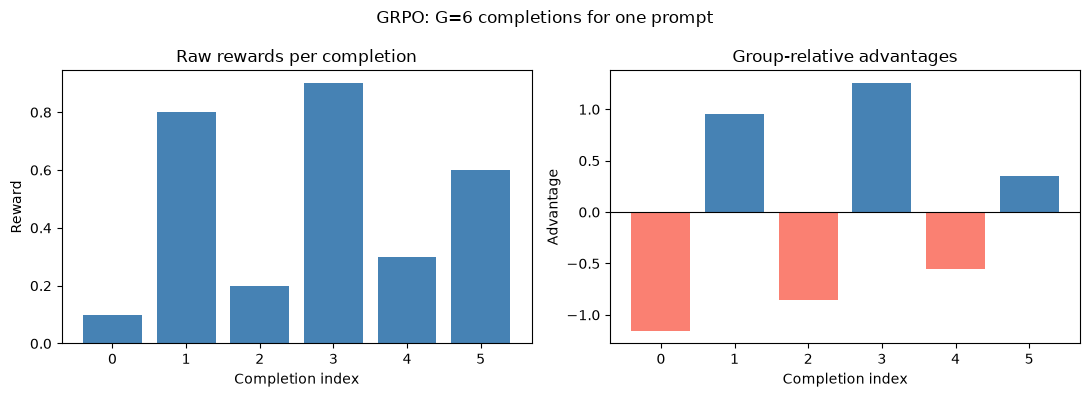

In [9]:
import torch.nn.functional as F

def grpo_advantage(rewards: list[float]) -> torch.Tensor:
    """
    Compute group-relative advantages for G completions.
    Normalises rewards within the group -- no trainable critic needed.
    """
    r  = torch.tensor(rewards, dtype=torch.float32)
    mu, std = r.mean(), r.std().clamp(min=1e-8)
    return (r - mu) / std                           # shape (G,)


def grpo_loss(log_p_new: torch.Tensor, log_p_old: torch.Tensor,
              advantages: torch.Tensor, eps: float = 0.2,
              beta: float = 0.1,
              log_p_ref: torch.Tensor = None) -> torch.Tensor:
    """
    GRPO policy gradient with clipping and optional KL penalty.
    All inputs: shape (G,) — one value per completion in the group.
    """
    ratio  = torch.exp(log_p_new - log_p_old)
    surr1  = ratio * advantages
    surr2  = torch.clamp(ratio, 1.0 - eps, 1.0 + eps) * advantages
    policy_loss = -torch.min(surr1, surr2).mean()

    kl = torch.tensor(0.0)
    if log_p_ref is not None:
        # KL(π_θ ‖ π_ref) ≈ exp(log_p_new - log_p_ref) - (log_p_new - log_p_ref) - 1
        kl = (torch.exp(log_p_new - log_p_ref)
              - (log_p_new - log_p_ref) - 1.0).mean()

    return policy_loss + beta * kl


# ── Toy simulation: G=6 completions for one prompt ───────────────────────────
rewards_example = [0.1, 0.8, 0.2, 0.9, 0.3, 0.6]
advantages      = grpo_advantage(rewards_example)

print("Rewards     :", [f"{r:.2f}" for r in rewards_example])
print("Advantages  :", [f"{a:.2f}" for a in advantages.tolist()])

# Simulate log-probs
G = len(rewards_example)
log_p_old  = torch.full((G,), -2.0)
log_p_new  = log_p_old + torch.randn(G) * 0.15   # small update
log_p_ref  = log_p_old.clone()

loss = grpo_loss(log_p_new, log_p_old, advantages, log_p_ref=log_p_ref)
print(f"\nGRPO loss   : {loss.item():.4f}")

# ── Visualise group advantages ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["steelblue" if a > 0 else "salmon" for a in advantages.tolist()]

axes[0].bar(range(G), rewards_example, color="steelblue")
axes[0].set(title="Raw rewards per completion", xlabel="Completion index", ylabel="Reward")

axes[1].bar(range(G), advantages.tolist(), color=colors)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="Group-relative advantages", xlabel="Completion index", ylabel="Advantage")

plt.suptitle(f"GRPO: G={G} completions for one prompt")
plt.tight_layout(); plt.show()


## Using Ollama for Group Sampling

GRPO generates $G$ completions per prompt using the *current policy*.
Below we use **Ollama** (local LLM) to simulate this, showing the full
reward / advantage pipeline on math reasoning problems.


In [10]:
import os, re
from openai import OpenAI

# Connect to OpenRouter or Ollama via standard OpenAI client
base_url = os.getenv("OPENAI_BASE_URL", "https://openrouter.ai/api/v1" if os.getenv("OPENROUTER_API_KEY") else "http://localhost:11434/v1")
api_key = os.getenv("OPENAI_API_KEY", os.getenv("OPENROUTER_API_KEY", "ollama"))
default_model = os.getenv("LLM_MODEL", "meta-llama/llama-3.2-3b-instruct" if "openrouter" in base_url else "llama3.2:1b")
client = OpenAI(base_url=base_url, api_key=api_key)

# If the chosen model isn't available locally, fall back to any installed one.
if "openrouter" not in base_url:
    try:
        available = [m.id for m in client.models.list().data]
    except Exception as e:
        raise RuntimeError(f"Can't reach Ollama at {base_url}. Start it with `ollama serve`.") from e
    if default_model not in available:
        if not available:
            raise RuntimeError(f"No Ollama models installed. Run: ollama pull {default_model}")
        print(f"'{default_model}' not found; using '{available[0]}' instead "
              f"(or run: ollama pull {default_model})")
        default_model = available[0]

def extract_number(text: str):
    """Extract the last number from a model response."""
    nums = re.findall(r"-?\d+(?:\.\d+)?", text)
    return float(nums[-1]) if nums else None

def math_reward(response: str, ground_truth: float) -> float:
    """Verifiable reward: 1.0 if correct, 0.0 otherwise (with format bonus)."""
    pred = extract_number(response)
    if pred is None:
        return 0.0
    correct = abs(pred - ground_truth) < 1e-3
    has_reasoning = len(response.split()) > 10        # bonus for showing work
    return (0.8 if correct else 0.0) + (0.2 if has_reasoning else 0.0)

def grpo_sample_group(prompt: str, model: str = default_model, G: int = 4) -> list[str]:
    """Sample G completions from an LLM via standard OpenAI API."""
    completions = []
    for _ in range(G):
        try:
            resp = client.chat.completions.create(
                model=model,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.8,
                max_tokens=100,
            )
            completions.append(resp.choices[0].message.content.strip())
        except Exception as e:
            raise RuntimeError(f"Sampling failed with model '{model}': {e}") from e
    return completions

# ── Run on a few math problems ────────────────────────────────────────────────
problems = [
    ("What is 17 × 8? Show your reasoning step by step.", 136),
    ("If a train travels at 60 mph for 2.5 hours, how many miles does it cover?", 150),
]

for problem_text, answer in problems:
    print(f"\nProblem: {problem_text}")
    print(f"Answer : {answer}")

    completions = grpo_sample_group(problem_text, G=4)
    rewards     = [math_reward(c, answer) for c in completions]
    advantages  = grpo_advantage(rewards)

    for i, (comp, r, a) in enumerate(zip(completions, rewards, advantages)):
        preview = comp[:80].replace("\n", " ") + ("…" if len(comp) > 80 else "")
        print(f"  [{i}] r={r:.2f}  A={a:.2f}  {preview}")

    print(f"  → Mean reward: {np.mean(rewards):.2f}  |  Std: {np.std(rewards):.2f}")


'llama3.2:1b' not found; using 'nemotron-3.5-bolt:e4b' instead (or run: ollama pull llama3.2:1b)

Problem: What is 17 × 8? Show your reasoning step by step.
Answer : 136
  [0] r=0.00  A=0.00  
  [1] r=0.00  A=0.00  
  [2] r=0.00  A=0.00  
  [3] r=0.00  A=0.00  
  → Mean reward: 0.00  |  Std: 0.00

Problem: If a train travels at 60 mph for 2.5 hours, how many miles does it cover?
Answer : 150
  [0] r=0.00  A=0.00  
  [1] r=0.00  A=0.00  
  [2] r=0.00  A=0.00  
  [3] r=0.00  A=0.00  
  → Mean reward: 0.00  |  Std: 0.00


## Training with TRL's GRPOTrainer

For actual policy updates, TRL provides `GRPOTrainer`.  It handles group
sampling, advantage computation, and the clipped policy gradient automatically.

> **Recommended model:** A small instruction-tuned model such as
> `Qwen/Qwen2.5-0.5B-Instruct` (500 M params) fits comfortably in CPU/MPS memory.


In [ ]:
from datasets import Dataset
from trl import GRPOConfig, GRPOTrainer

# ── Verifiable reward for simple arithmetic ───────────────────────────────────
def arithmetic_reward(completions, prompts=None, **kwargs):
    """
    Reward function passed to GRPOTrainer.
    completions: list of generated strings (one per group member)
    Returns:     list of float rewards
    """
    # Ground-truth answers encoded in the prompt after '='
    rewards = []
    for comp, prompt in zip(completions, prompts or [""]*len(completions)):
        match = re.search(r"=\s*(-?\d+(?:\.\d+)?)", prompt)
        gt    = float(match.group(1)) if match else None
        score = math_reward(comp, gt) if gt is not None else 0.0
        rewards.append(score)
    return rewards


# ── Minimal dataset of arithmetic problems ────────────────────────────────────
problems = [
    f"Calculate {a} + {b} = {a+b}. Show your work."
    for a, b in [(3, 5), (12, 7), (25, 38), (100, 47), (9, 91),
                 (14, 28), (50, 63), (7, 8)]
]
train_ds = Dataset.from_dict({"prompt": problems})

# ── GRPOConfig ────────────────────────────────────────────────────────────────
grpo_cfg = GRPOConfig(
    output_dir="./grpo_output",
    num_generations=4,          # G — completions per prompt
    learning_rate=5e-6,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    beta=0.04,                  # KL coefficient
    epsilon=0.2,                # clip range
    logging_steps=1,
    report_to="none",
)

grpo_trainer = GRPOTrainer(
    model="Qwen/Qwen2.5-0.5B-Instruct",
    args=grpo_cfg,
    reward_funcs=[arithmetic_reward],
    train_dataset=train_ds,
)

print("Training GRPO (1 epoch) …  this may take a few minutes on CPU.")
grpo_trainer.train()
print("Done.")


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Training GRPO (1 epoch) …  this may take a few minutes on CPU.


Step,Training Loss


---
## 4. Head-to-Head Comparison: PPO vs. DPO vs. GRPO

In [ ]:
import pandas as pd

comparison_matrix = [
    {
        "Paradigm": "PPO (RLHF)",
        "Models in VRAM": "4 (Actor, Critic, Ref, Reward)",
        "Reward Source": "Trained neural reward model",
        "Training Stability": "Low (sensitive to hyperparams)",
        "Best Use Case": "General subjective chatbot persona alignment"
    },
    {
        "Paradigm": "DPO",
        "Models in VRAM": "2 (Policy, Reference)",
        "Reward Source": "Implicit (derived from chosen/rejected pairs)",
        "Training Stability": "High (supervised cross-entropy style loss)",
        "Best Use Case": "Safety alignment, conversational preference tuning"
    },
    {
        "Paradigm": "GRPO (DeepSeek)",
        "Models in VRAM": "2 (Policy, Reference; NO Critic)",
        "Reward Source": "Rule-based verifiers or group rewards",
        "Training Stability": "High (group-normalized advantage)",
        "Best Use Case": "Complex reasoning, math problem-solving, code generation"
    }
]

df_comp = pd.DataFrame(comparison_matrix)
print("=== Alignment Paradigms Comparison ===")
print(df_comp.to_string(index=False))

## 5. Summary & Key Takeaways

1. **The Alignment Triad**: PPO pioneered RLHF, DPO made preference alignment practical on commodity hardware, and GRPO unlocked self-verifiable reasoning at scale.
2. **DPO Simplification**: DPO replaces the entire multi-stage RL training loop with a single binary cross-entropy loss over log-likelihood ratios.
3. **GRPO Efficiency**: By sampling $G$ outputs per prompt and normalizing reward within the group, GRPO eliminates the Critic model (saving ~50% VRAM) while providing an effective exploration policy for chain-of-thought reasoning models (DeepSeek-R1).